In [50]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [51]:
models = {
    "SVM": Pipeline([("scaler", StandardScaler()), ("model", SVC())]),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

before = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    before[name] = accuracy_score(y_test, model.predict(X_test))
    print(name, "CV:", cross_val_score(model, X_train, y_train, cv=5).mean())

SVM CV: 0.9714285714285715
Random Forest CV: 0.953846153846154
AdaBoost CV: 0.9692307692307693


In [52]:
params = {
    "SVM": {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
    "Random Forest": {"n_estimators": [50, 100], "max_depth": [5, 10]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]}
}

after = {}

for name, model in models.items():
    grid = GridSearchCV(model, params[name], cv=5)
    grid.fit(X_train, y_train)

    after[name] = accuracy_score(y_test, grid.predict(X_test))
    print(name, "Best Parameters:", grid.best_params_)

SVM Best Parameters: {'model__C': 0.1, 'model__kernel': 'linear'}
Random Forest Best Parameters: {'max_depth': 10, 'n_estimators': 100}
AdaBoost Best Parameters: {'learning_rate': 1, 'n_estimators': 100}


In [53]:
comparison = pd.DataFrame({
    "Before Optimization": before,
    "After Optimization": after
})

print(comparison)

               Before Optimization  After Optimization
SVM                       0.982456            0.982456
Random Forest             0.956140            0.956140
AdaBoost                  0.956140            0.956140


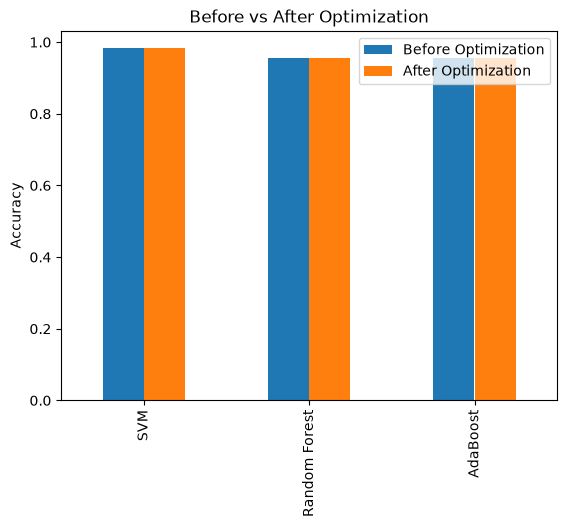

In [54]:
import matplotlib.pyplot as plt

comparison.plot(kind="bar")
plt.ylabel("Accuracy")
plt.title("Before vs After Optimization")
plt.show()